In [15]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/8/2022
# version ='1.0'

### Demo: An experiment on Newton's method implementation on an example in $R^{5000}$ 

In the text book {book-convex-2004}, section 9.5, 'Newton's method', a challenging experiment in $R^{10000}$ was discussed. In this demo, the similar minimization problem is

$$
\min f(x) = -{\sum_{i=1}^{n}\log(1-x_i^2)} - {\sum_{i=1}^{m}\log(b_i-a_i^Tx)}
$$

The gradient and the hessian is

$$
\begin{array}{rcl}
\nabla f(x) & = & \left[ \dfrac{2x}{1-x^2} \right] + A^T \dfrac{1}{(b-Ax)} \\
\\
\nabla^2 f(x) & = & \mathbf{diag}([\dfrac{2}{1-x^2} + \dfrac{4x^2}{(1-x^2)^2}]) + A^T \mathbf{diag}([\dfrac{1}{(b-Ax)^2}]) A \\
\end{array}
$$

The steps to generate $A, b$ are the following in order to make the minimization attainable (i.e. $\nabla f(x)=0$)
\begin{itemize}
\item  generate randomly $A=[a_{i,j}]\in R^{m\times n }$ with $a_{i,j}\in(0,1)$
\item generate randomly $\lambda \in (0, \gamma)^m$, where $\gamma$ is a heuristic range limit (e.g. $\gamma$ = 0.1 in the experiment)
\item generate $\beta=A^T\lambda$ 
\item let $x=\dfrac{1-\sqrt{(1+\beta^2)}}{\beta}$, which is $0<x<1$
\item let $b=\dfrac{1}{\lambda} + Ax$
\end{itemize}

In the Newton's method, the starting point, $x_0$ is set to be $-1+\epsilon$, where $\epsilon$ is the margin.

In the backtracking line search, $\alpha=0.01$, $\beta=0.5$.

The experiment result is for $n=5000, m=50000$.


More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).

In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
def my_f_fesasible(x, b, A):
    return np.all(b - A @ x > 0) and np.all(x ** 2 < 1)


def my_f(x, b, A):
    return - (np.sum(np.log(1 - x ** 2))).item() - (np.sum(np.log(b - A @ x))).item()


def my_gradient_f(x, b, A):
    return 2 * (x / (1 - x ** 2)) + A.T @ (1 / (b - A @ x))


def my_hessian_f(x, b, A):
    P_I = np.diag(np.squeeze(2 / (1 - x ** 2) + 4 * ((x ** 2) / ((1 - x ** 2) ** 2))))
    diag = np.diag(np.squeeze(1 / ((b - A @ x) ** 2)))
    P_II = A.T @ diag @ A
    hessian = P_I + P_II
    return hessian

In [18]:
def my_newton_step_decrement(x, args):
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    hessian_inv = np.linalg.inv(hessian)
    x_nt = -1 * hessian_inv @ gradient
    decrement = -1 * gradient.T @ x_nt
    return x_nt, decrement.item()

In [19]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    t = 1  # / np.linalg.norm(delta_x)
    while (not my_f_fesasible(x + delta_x * t, *args)) \
            or f(x + delta_x * t, *args) > f(x, *args) + alpha * t * ((df(x, *args).T @ delta_x).item()):
        t = beta * t
    return t

In [20]:
def plot_convergence(m, n):
    np.random.seed(1)
    A = np.random.rand(m, n)
    if not np.linalg.matrix_rank(A) == n:
        raise RuntimeError("rank(A) should be equal to n!")

    scale = 0.1
    Lambda = np.random.rand(m, 1) * scale
    Beta = A.T @ Lambda
    xp = (1 - np.sqrt(1 + Beta ** 2)) / Beta
    b = 1 / Lambda + A @ xp
    diff = A.T @ (1 / (b - A @ xp)) + (2 * xp) / (1 - xp ** 2)

    args = (b, A)
    f_min = my_f(xp, *args)

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-10

    # backtracking line search
    initial_margin = 1e-9
    x0 = -(1 - initial_margin) * np.ones([n, 1])
    x = x0
    x_nt, decrement = my_newton_step_decrement(x, args)
    fx = [my_f(x, *args)]
    iteration = 0
    while decrement / 2 > epsilon:
        print('Info: decrement = {}, fx={}'.format(decrement, fx[-1]))
        t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        x_next = x + t * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, args)

        fx.append(my_f(x, *args))
        iteration = iteration + 1

    print('Info: decrement = {}, fx={}'.format(decrement, fx[-1]))
    ax = plt.subplot(1, 1, 1)
    ax.semilogy(np.array(fx) - f_min, marker='x', label=r"backtracking line")

    diff = np.max((x - xp) ** 2)
    ax.grid()
    ax.legend()
    plt.show()

Info: decrement = 49.999998849887014, fx=-694.5163478873955
Info: decrement = 49.99999769977403, fx=-729.1737063653364
Info: decrement = 49.999995399548084, fx=-763.8310642932206
Info: decrement = 49.999990799096594, fx=-798.4884194140241
Info: decrement = 49.99998159819452, fx=-833.1457716268344
Info: decrement = 49.99996319639461, fx=-867.803116854456
Info: decrement = 49.99992639281139, fx=-902.4604482608875
Info: decrement = 49.999852785711425, fx=-937.1177520743875
Info: decrement = 49.9997055717773, fx=-971.7750006972865
Info: decrement = 49.999411144972505, fx=-1006.4321389037709
Info: decrement = 49.99882229561669, fx=-1041.0890562893383
Info: decrement = 49.99764461391987, fx=-1075.7455320401723
Info: decrement = 49.99528931858477, fx=-1110.4011245311826
Info: decrement = 49.99057900014233, fx=-1145.0549505586293
Info: decrement = 49.98115945211701, fx=-1179.7052438787514
Info: decrement = 49.962324711093046, fx=-1214.3484726637962
Info: decrement = 49.92467264585707, fx=-1248

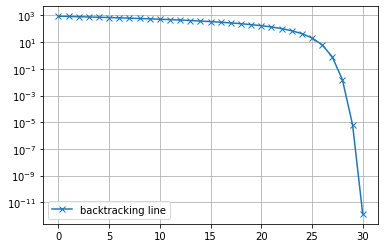

In [21]:
if __name__ == "__main__":
    plot_convergence(m=500, n=50)